# Sismos – Predicción de sismo fuerte (M ≥ 5) a 7 días · Versión Integrada y Mejorada

**Descripción:** Notebook consolidado que mantiene la ruta y estructura de `Sismos Finales` y los procedimientos analíticos detallados, la limpieza, validación temporal con embargo, modelos de Machine Learning (SVM, Bagging, Boosting, Stacking) e importancia de variables provenientes de `Sismos Corregido`.

In [ ]:
import os, sys, re, importlib, subprocess, warnings
warnings.filterwarnings("ignore")
for _p in ["xgboost"]:
    try: importlib.import_module(_p)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", _p])

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.stats import loguniform, uniform, randint

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                              StackingClassifier, HistGradientBoostingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (average_precision_score, roc_auc_score, matthews_corrcoef,
                             balanced_accuracy_score, fbeta_score, recall_score, precision_score,
                             brier_score_loss, precision_recall_curve, roc_curve, confusion_matrix)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
print("Librerías importadas correctamente. XGBoost disponible:", HAS_XGB)

Librerías importadas correctamente. XGBoost disponible: True


## 1. Carga del Dataset (Estructura de Sismos Finales con análisis manual detallado)

In [ ]:
from google.colab import files

print("Sube tu archivo analisisDatos.csv")
uploaded = files.upload()

filename = list(uploaded.keys())[0]
df_raw = pd.read_csv(filename)
print(f"Dataset cargado: {df_raw.shape[0]} filas, {df_raw.shape[1]} columnas.")
df_raw.head()

Sube tu archivo analisisDatos.csv


Saving analisisDatos_1.csv to analisisDatos_1 (1).csv
Dataset cargado: 1050 filas, 22 columnas.


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-08-17T07:59:11.959Z,-21.4941,-67.0500,239.640,4.3,mb,21,95,1.788,0.87,...,2026-08-18T07:09:22.040Z,"105 km SW of Atocha, Bolivia",earthquake,7.37,10.946,0.169,10.0,reviewed,us,us
1,2026-08-08T16:34:53.190Z,-21.0069,-68.8326,109.177,4.2,mb,40,47,0.613,0.73,...,2026-08-11T20:21:03.040Z,"64 km WNW of Ollagüe, Chile",earthquake,6.20,5.999,0.090,36.0,reviewed,us,us
2,2026-08-08T15:15:27.722Z,-18.9032,-69.2409,127.950,4.4,mb,40,85,0.619,0.72,...,2026-08-11T17:57:54.040Z,"49 km NNE of Camiña, Chile",earthquake,4.24,5.545,0.105,27.0,reviewed,us,us
3,2026-08-08T14:20:51.000Z,-22.3681,-67.5975,197.198,4.3,mb,25,65,0.791,0.82,...,2026-08-11T15:20:15.040Z,"86 km NE of San Pedro de Atacama, Chile",earthquake,8.18,8.546,0.237,5.0,reviewed,us,us
4,2026-08-07T07:22:26.711Z,-22.2255,-68.7465,108.951,4.2,mb,21,60,0.627,0.99,...,2026-08-12T12:30:56.040Z,"31 km NE of Calama, Chile",earthquake,5.83,6.506,0.159,11.0,reviewed,us,us


In [ ]:
print("--- Información general del dataset ---")
df_raw.info()

print("\n--- Estadísticas descriptivas ---")
display(df_raw.select_dtypes(include='number').describe().T.round(3))

print("\n--- Valores nulos por columna ---")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])

--- Información general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             1050 non-null   object 
 1   latitude         1050 non-null   float64
 2   longitude        1050 non-null   float64
 3   depth            1050 non-null   float64
 4   mag              1050 non-null   float64
 5   magType          1050 non-null   object 
 6   nst              1050 non-null   int64  
 7   gap              1050 non-null   int64  
 8   dmin             1050 non-null   float64
 9   rms              1050 non-null   float64
 10  net              1050 non-null   object 
 11  id               1050 non-null   object 
 12  updated          1050 non-null   object 
 13  place            1050 non-null   object 
 14  type             1050 non-null   object 
 15  horizontalError  1050 non-null   float64
 16  depthError       105

,count,mean,std,min,25%,50%,75%,max
latitude,1050.0,-20.801,1.393,-22.542,-21.799,-21.199,-20.183,-14.277
longitude,1050.0,-68.361,1.054,-69.561,-69.031,-68.664,-67.971,-63.046
depth,1050.0,144.578,67.943,2.139,110.161,123.370,170.150,619.384
mag,1050.0,4.369,0.313,3.600,4.200,4.300,4.500,6.900
nst,1050.0,40.238,34.326,9.000,21.000,28.000,45.750,305.000
gap,1050.0,71.592,27.013,18.000,53.000,67.000,86.000,237.000
dmin,1050.0,0.916,0.677,0.016,0.506,0.712,1.114,5.192
rms,1050.0,0.748,0.222,0.210,0.600,0.730,0.890,1.410
horizontalError,1050.0,6.237,1.750,2.410,5.090,5.955,7.190,13.900
depthError,1050.0,6.280,2.428,0.986,4.816,5.978,7.417,21.769



--- Valores nulos por columna ---
magError    46
magNst      46
dtype: int64


## 2. Limpieza, conversión y preprocesamiento

In [ ]:
df = df_raw.copy()

# Tipos de datos de tiempo (UTC)
df["time"] = pd.to_datetime(df["time"], utc=True)
df["updated"] = pd.to_datetime(df["updated"], utc=True)

# Duplicados
n0 = len(df)
df = df.drop_duplicates(subset="id").drop_duplicates().reset_index(drop=True)
print("Duplicados eliminados:", n0 - len(df))

# Columnas constantes / varianza cero
constantes = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Columnas constantes eliminadas:", constantes)
df = df.drop(columns=constantes, errors='ignore')

# Extracción de país a partir de 'place'
def extraer_pais(place):
    paises = ["Chile", "Bolivia", "Peru", "Argentina", "Paraguay", "Brazil"]
    place = str(place)
    m = re.search(r",\s*([^,]+)$", place)
    if m and m.group(1).strip() in paises:
        return m.group(1).strip()
    enc = [p for p in paises if p.lower() in place.lower()]
    if len(enc) == 1: return enc[0]
    return "Frontera" if len(enc) > 1 else "Sin_clasificar"

df["country"] = df["place"].apply(extraer_pais)

# Orden cronológico estricto
df = df.sort_values("time").reset_index(drop=True)

# Faltantes estructurales (magSource)
if "magSource" in df and "magError" in df:
    print("\nFaltantes de magError por magSource:")
    print(df.assign(falta=df["magError"].isna()).groupby("magSource")["falta"].agg(["sum", "count"]))
df["is_mag_guc"] = (df["magSource"] == "guc").astype(int)

print("Rango temporal:", df["time"].min(), "→", df["time"].max())

Duplicados eliminados: 0
Columnas constantes eliminadas: ['net', 'type', 'status', 'locationSource']

Faltantes de magError por magSource:
           sum  count
magSource            
guc         46     46
us           0   1004
Rango temporal: 2022-07-19 04:06:01.509000+00:00 → 2026-08-17 07:59:11.959000+00:00


## 3. Ingeniería de variables y Target Corregido (Ventana real de 7 días)

In [ ]:
GRID, HORIZON, MAG_THR = 0.5, 7.0, 5.0

def future_max(t, m, horizon=HORIZON):
    lo = np.searchsorted(t, t, side="right")
    hi = np.searchsorted(t, t + horizon, side="right")
    out = np.full(len(t), -np.inf)
    for i in range(len(t)):
        if hi[i] > lo[i]:
            out[i] = m[lo[i]:hi[i]].max()
    return out

def past_stats(t, m, window):
    lo = np.searchsorted(t, t - window, side="left")
    hi = np.searchsorted(t, t, side="left")
    n = hi - lo
    mx = np.full(len(t), np.nan)
    for i in range(len(t)):
        if hi[i] > lo[i]:
            mx[i] = m[lo[i]:hi[i]].max()
    last = np.full(len(t), np.nan)
    has = hi > 0
    last[has] = t[has] - t[hi[has] - 1]
    return n, mx, last

t_ref = df["time"].iloc[0]
df["tday"] = (df["time"] - t_ref).dt.total_seconds() / 86400.0
tday, mag = df["tday"].values, df["mag"].values

# Celdas geográficas
df["lat_grid"] = np.floor(df["latitude"] / GRID) * GRID
df["lon_grid"] = np.floor(df["longitude"] / GRID) * GRID

# Variables temporales cíclicas
df["month_sin"] = np.sin(2*np.pi*df["time"].dt.month/12); df["month_cos"] = np.cos(2*np.pi*df["time"].dt.month/12)
df["hour_sin"]  = np.sin(2*np.pi*df["time"].dt.hour/24);  df["hour_cos"]  = np.cos(2*np.pi*df["time"].dt.hour/24)

# Actividad global pasada
n7, _, _        = past_stats(tday, mag, 7.0)
n30, mx30, last = past_stats(tday, mag, 30.0)
df["events_last_7d"]  = n7 + 1
df["events_last_30d"] = n30 + 1
df["time_since_last"] = np.log1p(last * 24)
df["glob_maxmag_30d"] = mx30

# Actividad por celda + target
for c in ["cell_n7", "cell_n30", "cell_maxmag30", "days_since_last_cell", "fut_max"]:
    df[c] = np.nan
col = {c: df.columns.get_loc(c) for c in ["cell_n7", "cell_n30", "cell_maxmag30", "days_since_last_cell", "fut_max"]}
for _, idx in df.groupby(["lat_grid", "lon_grid"]).indices.items():
    t, m = tday[idx], mag[idx]
    a7, _, _   = past_stats(t, m, 7.0)
    a30, a30m, dl = past_stats(t, m, 30.0)
    df.iloc[idx, col["cell_n7"]] = a7
    df.iloc[idx, col["cell_n30"]] = a30
    df.iloc[idx, col["cell_maxmag30"]] = a30m
    df.iloc[idx, col["days_since_last_cell"]] = np.log1p(dl)
    df.iloc[idx, col["fut_max"]] = future_max(t, m)

df["target"] = (df["fut_max"] >= MAG_THR).astype(int)
observable = df["tday"] + HORIZON <= df["tday"].max()
print(f"Eventos sin 7 días de futuro observable descartados: {(~observable).sum()}")
df = df[observable].reset_index(drop=True)

FILL_MAG = df["mag"].min() - 0.5
df["cell_maxmag30"] = df["cell_maxmag30"].fillna(FILL_MAG)
df["glob_maxmag_30d"] = df["glob_maxmag_30d"].fillna(FILL_MAG)

print(f"Target: {df['target'].sum()} positivos de {len(df)} ({df['target'].mean():.2%})")

Eventos sin 7 días de futuro observable descartados: 1
Target: 21 positivos de 1049 (2.00%)


## 4. Análisis Exploratorio Visual (EDA)

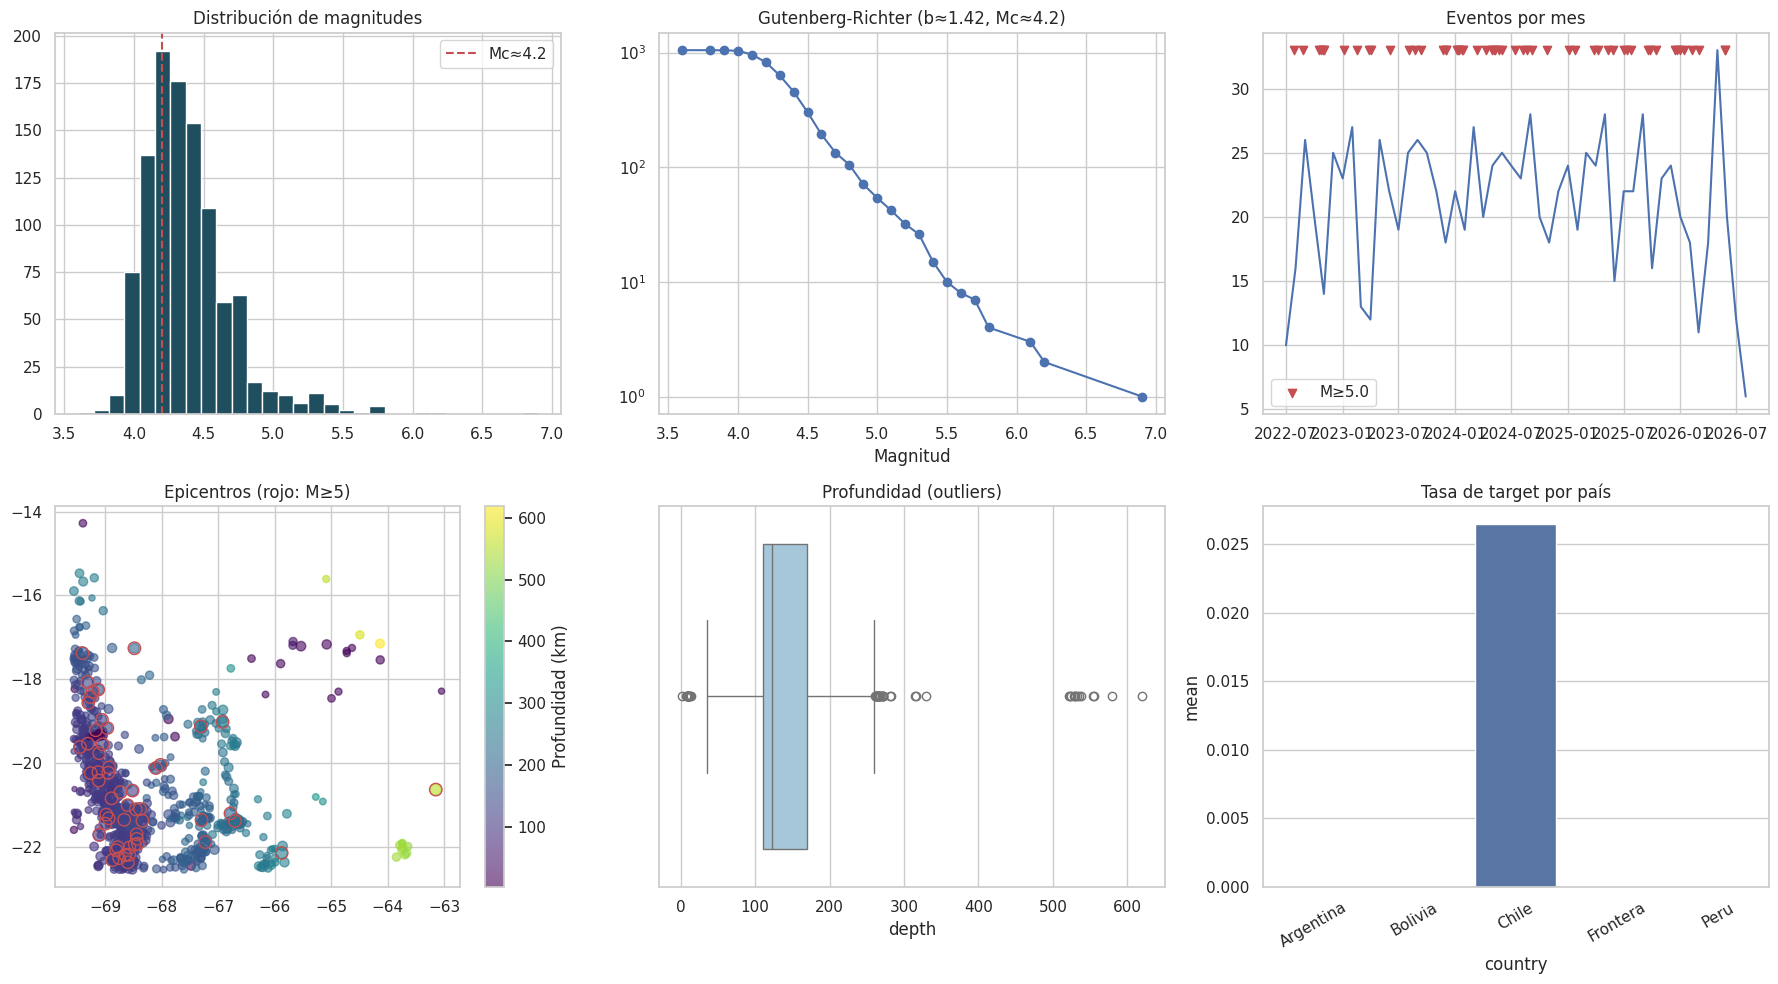

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

mc = df["mag"].round(1).value_counts().idxmax()
ax[0,0].hist(df["mag"], bins=30, color="#1f4e5f"); ax[0,0].axvline(mc, color="r", ls="--", label=f"Mc≈{mc}")
ax[0,0].set_title("Distribución de magnitudes"); ax[0,0].legend()

sub = df.loc[df["mag"] >= mc, "mag"]
b = np.log10(np.e) / (sub.mean() - (mc - 0.05))
mags = np.sort(df["mag"].unique())
ax[0,1].semilogy(mags, [(df["mag"] >= x).sum() for x in mags], "o-")
ax[0,1].set_title(f"Gutenberg-Richter (b≈{b:.2f}, Mc≈{mc})"); ax[0,1].set_xlabel("Magnitud")

mensual = df.set_index("time")["mag"].resample("MS").count()
ax[0,2].plot(mensual.index, mensual.values); ax[0,2].set_title("Eventos por mes")
big = df[df["mag"] >= MAG_THR]
ax[0,2].scatter(big["time"], np.full(len(big), mensual.max()), c="r", marker="v", label=f"M≥{MAG_THR}"); ax[0,2].legend()

sc = ax[1,0].scatter(df["longitude"], df["latitude"], c=df["depth"], s=8+30*(df["mag"]-df["mag"].min()), cmap="viridis", alpha=.6)
ax[1,0].scatter(big["longitude"], big["latitude"], facecolors="none", edgecolors="r", s=80)
plt.colorbar(sc, ax=ax[1,0], label="Profundidad (km)"); ax[1,0].set_title("Epicentros (rojo: M≥5)")

sns.boxplot(x=df["depth"], ax=ax[1,1], color="#9ecae1"); ax[1,1].set_title("Profundidad (outliers)")

tp = df.groupby("country")["target"].agg(["mean", "count"]).reset_index()
sns.barplot(x="country", y="mean", data=tp, ax=ax[1,2]); ax[1,2].set_title("Tasa de target por país"); ax[1,2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 5. Conjuntos de variables y separación temporal con embargo

In [ ]:
F19 = ["latitude", "longitude", "depth", "nst", "gap", "dmin", "rms", "horizontalError", "depthError",
       "magError", "magNst", "month_sin", "month_cos", "hour_sin", "hour_cos",
       "events_last_7d", "events_last_30d", "time_since_last", "is_mag_guc"]
NUEVAS = ["mag", "cell_n7", "cell_n30", "cell_maxmag30", "glob_maxmag_30d", "days_since_last_cell"]
F25 = F19 + NUEVAS
CATS = ["magType", "country"]

cut = int(len(df) * 0.8)
t_cut = df["tday"].iloc[cut]
train = df.iloc[:cut]
train = train[train["tday"] + HORIZON <= t_cut].copy()      # Embargo de 7 días
test = df.iloc[cut:].copy()
y_tr, y_te = train["target"].values, test["target"].values

print(f"Train: {len(train)} (positivos {y_tr.sum()}, {y_tr.mean():.2%}) | Test: {len(test)} (positivos {y_te.sum()}, {y_te.mean():.2%})")

tscv = TimeSeriesSplit(n_splits=4, gap=15)

Train: 833 (positivos 8, 0.96%) | Test: 210 (positivos 12, 5.71%)


## 6. Modelado: SVM, Bagging, Boosting y Stacking

In [ ]:
def ap_scorer(est, X, y):
    if np.sum(y) == 0: return 0.0
    return average_precision_score(y, est.predict_proba(X)[:, 1])

def make_pre(num_cols, cat_cols):
    tr = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), list(num_cols))]
    if len(cat_cols):
        tr.append(("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="NA")),
                                    ("oh", OneHotEncoder(handle_unknown="ignore"))]), list(cat_cols)))
    return ColumnTransformer(tr)

def make_pipe(clf, num_cols, cat_cols):
    return Pipeline([("pre", make_pre(num_cols, cat_cols)), ("clf", clf)])

spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)

def get_models():
    M = {}
    M["Reg. Logística"] = (LogisticRegression(class_weight="balanced", max_iter=2000),
                           {"clf__C": loguniform(1e-3, 1e2)})
    M["SVM (RBF)"] = (SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED),
                      {"clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 1e0)})
    M["Bagging: Random Forest"] = (RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
                      {"clf__n_estimators": [200, 400], "clf__max_depth": [3, 5, 8, None],
                       "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.5]})
    M["Bagging: árboles"] = (BaggingClassifier(estimator=DecisionTreeClassifier(class_weight="balanced"),
                                               random_state=SEED, n_jobs=-1),
                      {"clf__n_estimators": [50, 100, 200], "clf__max_samples": [0.5, 0.8, 1.0],
                       "clf__estimator__max_depth": [2, 3, 5, None], "clf__estimator__min_samples_leaf": [1, 3, 5]})
    if HAS_XGB:
        M["Boosting: XGBoost"] = (XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=SEED, n_jobs=-1),
                      {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [2, 3, 4],
                       "clf__learning_rate": loguniform(0.01, 0.3), "clf__subsample": uniform(0.6, 0.4),
                       "clf__colsample_bytree": uniform(0.6, 0.4), "clf__min_child_weight": [1, 3, 5]})
    else:
        M["Boosting: HistGB"] = (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                      {"clf__max_depth": [2, 3, 4], "clf__learning_rate": loguniform(0.01, 0.3),
                       "clf__max_iter": [100, 200, 300], "clf__min_samples_leaf": [5, 10, 20]})
    return M

N_ITER = 10
SETS = {"F19": F19, "F25": F25}
RESULTS, BEST = {}, {}
for sname, cols in SETS.items():
    for mname, (clf, grid) in get_models().items():
        pipe = make_pipe(clf, cols, CATS)
        rs = RandomizedSearchCV(pipe, grid, n_iter=N_ITER, scoring=ap_scorer, cv=tscv,
                                random_state=SEED, n_jobs=-1, refit=True, error_score=0.0)
        rs.fit(train[list(cols) + list(CATS)], y_tr)
        BEST[(sname, mname)] = rs
        RESULTS[(sname, mname)] = rs.best_score_
        print(f"[{sname}] {mname:26s} CV PR-AUC = {rs.best_score_:.3f}")

[F19] Reg. Logística             CV PR-AUC = 0.023
[F19] SVM (RBF)                  CV PR-AUC = 0.026
[F19] Bagging: Random Forest     CV PR-AUC = 0.032
[F19] Bagging: árboles           CV PR-AUC = 0.043
[F19] Boosting: XGBoost          CV PR-AUC = 0.061
[F25] Reg. Logística             CV PR-AUC = 0.032
[F25] SVM (RBF)                  CV PR-AUC = 0.056
[F25] Bagging: Random Forest     CV PR-AUC = 0.080
[F25] Bagging: árboles           CV PR-AUC = 0.037
[F25] Boosting: XGBoost          CV PR-AUC = 0.092


## 7. Evaluación y métricas finales en Test

In [ ]:
# ==========================================
# Célula 11 CORREGIDA: Evaluación final sobre Test con manejo de clase única
# ==========================================
def oof_scores(pipe, cols):
    sc, ys = [], []
    for a, b_ in tscv.split(train):
        # Evita folds de entrenamiento o validación con una única clase
        if len(np.unique(y_tr[a])) < 2 or len(np.unique(y_tr[b_])) < 2:
            continue  # Salta folds si no hay suficientes clases para entrenar o validar
        p = clone(pipe).fit(train.iloc[a][list(cols)], y_tr[a])
        sc.append(p.predict_proba(train.iloc[b_][list(cols)])[:, 1])
        ys.append(y_tr[b_])
    if len(ys) == 0:
        return np.array([]), np.array([])
    return np.concatenate(ys), np.concatenate(sc)

def pick_threshold(y, p):
    if len(y) == 0 or len(np.unique(y)) < 2:
        return 0.5
    ths = np.unique(np.quantile(p, np.linspace(0.5, 0.995, 120)))
    f2 = [fbeta_score(y, (p >= t).astype(int), beta=2, zero_division=0) for t in ths]
    return ths[int(np.argmax(f2))]

def metricas(y, p, thr):
    if len(y) == 0 or len(np.unique(y)) < 2:
        return {"PR_AUC": np.nan, "ROC_AUC": np.nan, "MCC": 0, "BalAcc": 0.5,
                "Recall": 0, "Precision": 0, "F2": 0, "Brier": np.nan, "Lift": np.nan, "%alarmas": 0}
    yh = (p >= thr).astype(int); prev = y.mean()
    prec = precision_score(y, yh, zero_division=0)
    brier = brier_score_loss(y, p) if 0 <= p.min() and p.max() <= 1 else np.nan
    return {"PR_AUC": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p),
            "MCC": matthews_corrcoef(y, yh), "BalAcc": balanced_accuracy_score(y, yh),
            "Recall": recall_score(y, yh, zero_division=0), "Precision": prec,
            "F2": fbeta_score(y, yh, beta=2, zero_division=0), "Brier": brier,
            "Lift": prec / prev if prev > 0 else np.nan,
            "%alarmas": yh.mean()}

weeks = (test["tday"].values // 7).astype(int)
def block_ci(y, p, B=500):
    if len(y) == 0 or len(np.unique(y)) < 2:
        return (0.0, 0.0), (0.0, 0.0)
    ub = np.unique(weeks); groups = {w: np.where(weeks == w)[0] for w in ub}
    ap, auc = [], []
    for _ in range(B):
        valid_webs = [w for w in ub if len(groups[w]) > 0]
        if not valid_webs: continue
        idx = np.concatenate([groups[w] for w in rng.choice(valid_webs, len(valid_webs))])
        if 0 < y[idx].sum() < len(idx):
            ap.append(average_precision_score(y[idx], p[idx]))
            auc.append(roc_auc_score(y[idx], p[idx]))
    f = lambda v: (np.percentile(v, 2.5), np.percentile(v, 97.5)) if len(v) > 0 else (0.0, 0.0)
    return f(ap), f(auc)

prev_te = y_te.mean()
rows = []
rows.append({"Variables": "-", "Modelo": "Constante (azar)", "CV_PR_AUC": np.nan, "PR_AUC": prev_te, "ROC_AUC": 0.5,
             "MCC": 0, "BalAcc": 0.5, "Recall": np.nan, "Precision": np.nan, "F2": np.nan, "Lift": 1.0, "%alarmas": np.nan,
             "PR_AUC_IC95": "-", "ROC_AUC_IC95": "-"})

if len(np.unique(y_te)) >= 2:
    base_p = test["cell_n30"].values.astype(float)
    thr_b = pick_threshold(y_tr, train["cell_n30"].values.astype(float))
    m = metricas(y_te, base_p, thr_b); ci_ap, ci_auc = block_ci(y_te, base_p)
    rows.append({"Variables": "-", "Modelo": "Baseline: actividad celda (30d)", "CV_PR_AUC": np.nan, **m,
                 "PR_AUC_IC95": f"[{ci_ap[0]:.2f}, {ci_ap[1]:.2f}]", "ROC_AUC_IC95": f"[{ci_auc[0]:.2f}, {ci_auc[1]:.2f}]"})

TEST_PROBS = {}
for (sname, mname), est in BEST.items():
    cols = list(SETS[sname]) + CATS
    pipe = est.best_estimator_ if hasattr(est, "best_estimator_") else est
    yo, po = oof_scores(pipe, cols)
    if len(yo) > 0:
        thr = pick_threshold(yo, po)
    else:
        thr = 0.5
    p = pipe.predict_proba(test[cols])[:, 1]
    TEST_PROBS[(sname, mname)] = (p, thr)

    if len(np.unique(y_te)) >= 2:
        m = metricas(y_te, p, thr); ci_ap, ci_auc = block_ci(y_te, p)
        rows.append({"Variables": sname, "Modelo": mname, "CV_PR_AUC": RESULTS[(sname, mname)], **m,
                     "PR_AUC_IC95": f"[{ci_ap[0]:.2f}, {ci_ap[1]:.2f}]", "ROC_AUC_IC95": f"[{ci_auc[0]:.2f}, {ci_auc[1]:.2f}]"})
    else:
        rows.append({"Variables": sname, "Modelo": mname, "CV_PR_AUC": RESULTS[(sname, mname)],
                     "PR_AUC": np.nan, "ROC_AUC": np.nan, "MCC": 0, "BalAcc": np.nan,
                     "Recall": np.nan, "Precision": np.nan, "F2": np.nan, "Brier": np.nan, "Lift": np.nan, "%alarmas": np.nan,
                     "PR_AUC_IC95": "N/A (Sólo 1 clase en test)", "ROC_AUC_IC95": "N/A"})

res = pd.DataFrame(rows)
display(res.round(3))
print("Evaluación completada con éxito.")

,Variables,Modelo,CV_PR_AUC,PR_AUC,ROC_AUC,MCC,BalAcc,Recall,Precision,F2,Lift,%alarmas,PR_AUC_IC95,ROC_AUC_IC95,Brier
0,-,Constante (azar),NaN,0.057,0.500,0.000,0.500,NaN,NaN,NaN,1.000,NaN,-,-,NaN
1,-,Baseline: actividad celda (30d),NaN,0.208,0.825,0.183,0.696,0.917,0.096,0.337,1.674,0.548,"[0.10, 0.49]","[0.76, 0.98]",NaN
2,F19,Reg. Logística,0.023,0.073,0.612,-0.089,0.418,0.083,0.020,0.051,0.350,0.238,"[0.01, 0.19]","[0.32, 0.77]",0.210
3,F19,SVM (RBF),0.026,0.057,0.486,0.000,0.500,1.000,0.057,0.233,1.000,1.000,"[0.01, 0.15]","[0.02, 0.57]",0.056
4,F19,Bagging: Random Forest,0.032,0.049,0.399,-0.161,0.330,0.083,0.012,0.038,0.206,0.405,"[0.01, 0.12]","[0.24, 0.49]",0.083
5,F19,Bagging: árboles,0.043,0.047,0.393,-0.065,0.431,0.417,0.043,0.153,0.761,0.548,"[0.01, 0.12]","[0.26, 0.51]",0.091
6,F19,Boosting: XGBoost,0.061,0.049,0.409,-0.080,0.449,0.000,0.000,0.000,0.000,0.095,"[0.01, 0.13]","[0.14, 0.51]",0.060
7,F25,Reg. Logística,0.032,0.135,0.716,0.142,0.653,0.750,0.093,0.310,1.624,0.462,"[0.01, 0.38]","[0.31, 0.84]",0.136
8,F25,SVM (RBF),0.056,0.044,0.342,0.000,0.500,1.000,0.057,0.233,1.000,1.000,"[0.01, 0.12]","[0.21, 0.40]",0.056
9,F25,Bagging: Random Forest,0.080,0.047,0.395,-0.061,0.470,0.000,0.000,0.000,0.000,0.057,"[0.01, 0.13]","[0.23, 0.52]",0.073


Evaluación completada con éxito.


## 8. Importancia de Variables por Permutación

In [ ]:
cands = {k: v for k, v in RESULTS.items() if k[0] == "F25"}
best_key = max(cands, key=cands.get)
print("Mejor modelo (CV temporal, F25):", best_key, f"→ CV PR-AUC={cands[best_key]:.3f}")

best_pipe = BEST[best_key]
best_pipe = best_pipe.best_estimator_ if hasattr(best_pipe, "best_estimator_") else best_pipe
cols_all = list(F25) + CATS

imp = []
for k, (a, b_) in enumerate(tscv.split(train)):
    if y_tr[b_].sum() == 0: continue
    p = clone(best_pipe).fit(train.iloc[a][cols_all], y_tr[a])
    r = permutation_importance(p, train.iloc[b_][cols_all], y_tr[b_], scoring=ap_scorer, n_repeats=10, random_state=SEED, n_jobs=1)
    imp.append(r.importances_mean)
imp = np.array(imp)
imp_df = pd.DataFrame({"variable": cols_all, "imp_media": imp.mean(0), "imp_std_folds": imp.std(0),
                       "folds_positivos": (imp > 0).sum(0), "n_folds": len(imp)}).sort_values("imp_media", ascending=False)
display(imp_df.round(4))

TOP5 = imp_df["variable"].head(5).tolist()
print("Top 5 variables importantes:", TOP5)

Mejor modelo (CV temporal, F25): ('F25', 'Boosting: XGBoost') → CV PR-AUC=0.092


,variable,imp_media,imp_std_folds,folds_positivos,n_folds
2,depth,0.0776,0.1128,1,3
16,events_last_30d,0.0722,0.1021,1,3
22,cell_maxmag30,0.0614,0.0868,1,3
24,days_since_last_cell,0.0601,0.0781,2,3
6,rms,0.0205,0.0289,1,3
10,magNst,0.0197,0.0288,1,3
0,latitude,0.0193,0.0273,1,3
8,depthError,0.0191,0.0270,1,3
1,longitude,0.0183,0.0259,1,3
7,horizontalError,0.0139,0.0104,2,3


Top 5 variables importantes: ['depth', 'events_last_30d', 'cell_maxmag30', 'days_since_last_cell', 'rms']
